手写数字识别示例

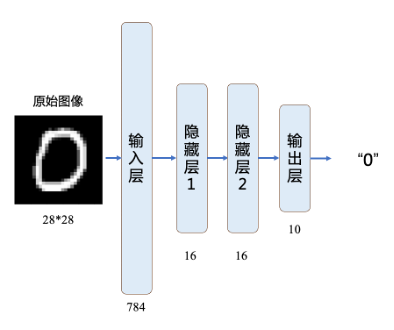

# **第一种方法：用上述图示的全连接网络，第一个隐藏层有16个神经元，第二个有16个神经元，输出层有10个神经元**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Dense, Flatten
from keras.utils import to_categorical
from keras.optimizers import Adam

In [3]:
#加载MNIST数据集
(x_train, y_train), (x_test, y_test) = mnist.load_data()

#数据归一化 (0-255 -> 0-1)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [ ]:
print("X_train original shape", x_train.shape)
print("y_train original shape", y_train.shape)

In [ ]:
for i in range(20):
    plt.subplot(4,5,i+1)
    plt.imshow(x_train[i], cmap='gray', interpolation='none')
    plt.title("Class {}".format(y_train[i]))

In [6]:
# 将标签转换为one-hot编码
# 0 -> [1, 0, 0, 0, 0, 0, 0, 0, 0]
# 1 -> [0, 1, 0, 0, 0, 0, 0, 0, 0]
# 2 -> [0, 0, 1, 0, 0, 0, 0, 0, 0]
# etc.
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

In [ ]:
# 3. 构建模型

model = Sequential() #创建空模型

model.add(Flatten(input_shape=(28,28))) # 展平层，将28x28图像转为784维向量
model.add(Dense(16, activation='relu')) # 第一个隐藏层，16个神经元
model.add(Dense(16, activation='relu')) # 第二个隐藏层，16个神经元
model.add(Dense(10, activation='softmax')) # 输出层，10个神经元对应10个数字类别

In [ ]:
model.summary()

In [ ]:
# 4. 编译模型

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
# 5. 训练模型

history = model.fit(x_train, y_train_onehot,
                    batch_size=32,
                    epochs=10,
                    validation_split=0.2, #使用20%训练数据作为验证集
                    verbose=1)

In [ ]:
# 6. 评估模型

# 在测试集上评估
test_loss, test_acc = model.evaluate(x_test, y_test_onehot, verbose=0)
print(f"\n测试集准确率：{test_acc:.4f}")

In [ ]:
# 7. 绘制学习曲线

# 绘制训练曲线
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],label='training acc')
plt.plot(history.history['val_accuracy'],label='validation acc')
plt.title('acc curve')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='training loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.title('loss curve')
plt.legend()
plt.show()

In [ ]:
# The predict_classes function outputs the highest probability class
# according to the trained classifier for each input example.
predict_x=model.predict(x_test)
predicted_classes=np.argmax(predict_x,axis=1)
# Check which items we got right / wrong
correct_indices = np.nonzero(predicted_classes == y_test)[0]
incorrect_indices = np.nonzero(predicted_classes != y_test)[0]

In [ ]:
plt.figure()
for i, correct in enumerate(correct_indices[:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[correct].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Predicted {}, Class {}".format(predicted_classes[correct], y_test[correct]))

plt.figure()
for i, incorrect in enumerate(incorrect_indices[:9]):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[incorrect].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("Predicted {}, Class {}".format(predicted_classes[incorrect], y_test[incorrect]))

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted_classes)
labels = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

disp.plot(cmap=plt.cm.Blues)
plt.show()

X_train original shape (60000, 28, 28)
y_train original shape (60000,)


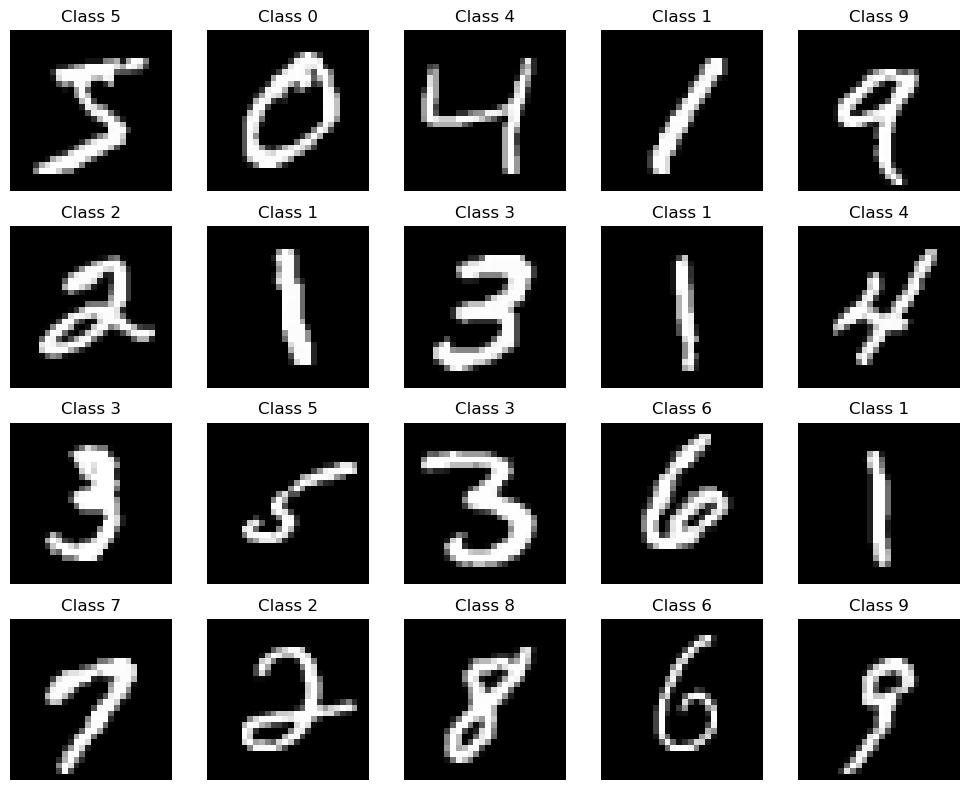

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 16)                  │          12,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             170 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 13,002 (50.79 KB)

 Trainable params: 13,002 (50.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7377 - loss: 0.8641 - val_accuracy: 0.9205 - val_loss: 0.2728
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9220 - loss: 0.2748 - val_accuracy: 0.9396 - val_loss: 0.2173
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9358 - loss: 0.2215 - val_accuracy: 0.9427 - val_loss: 0.2035
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9414 - loss: 0.2004 - val_accuracy: 0.9458 - val_loss: 0.1922
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9466 - loss: 0.1792 - val_accuracy: 0.9422 - val_loss: 0.1997
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9529 - loss: 0.1610 - val_accuracy: 0.9439 - val_loss: 0.1927
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9547 - loss: 0.1547 - val_accuracy: 0.9523 - val_loss: 0.1691
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9562 - loss: 0.1454 -

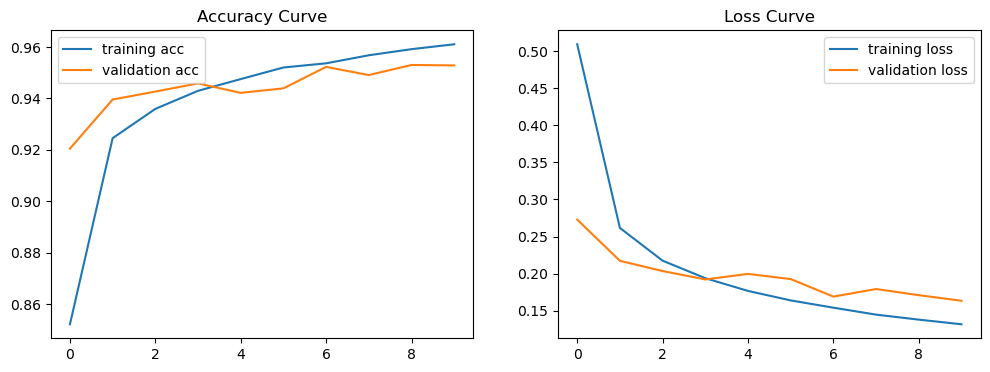

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


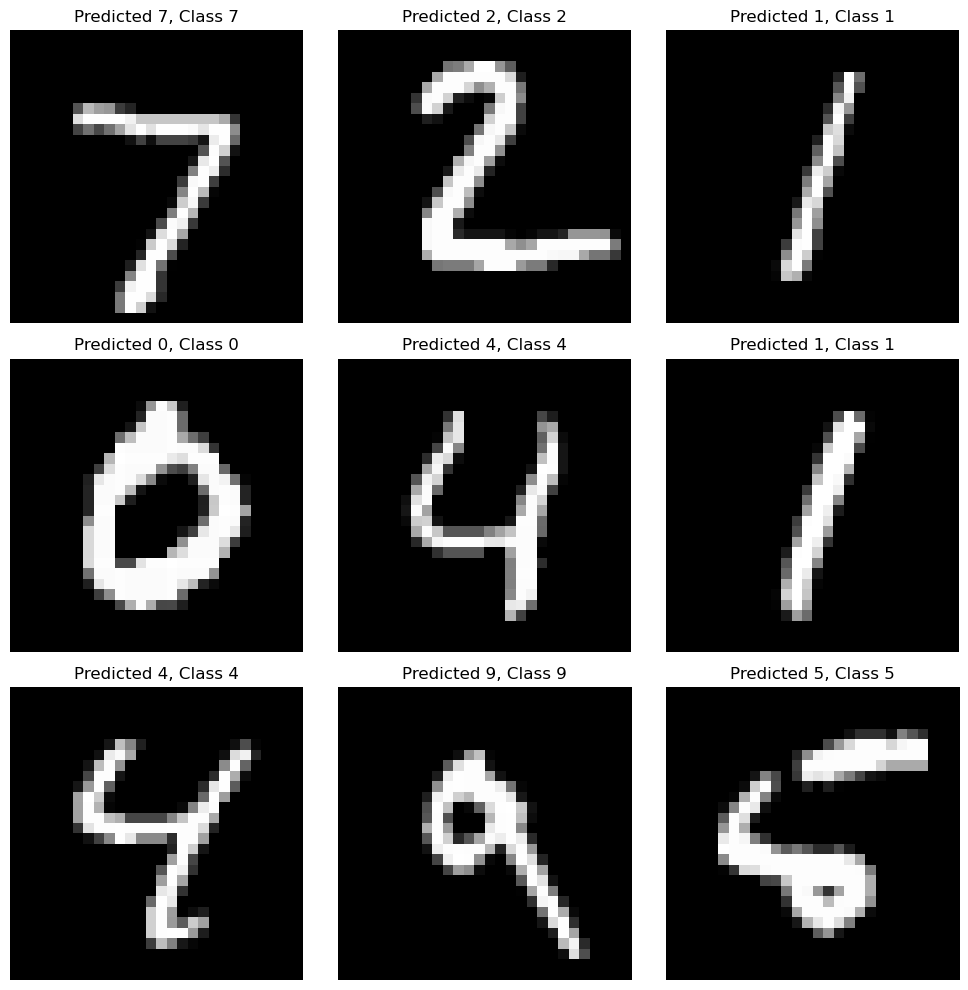

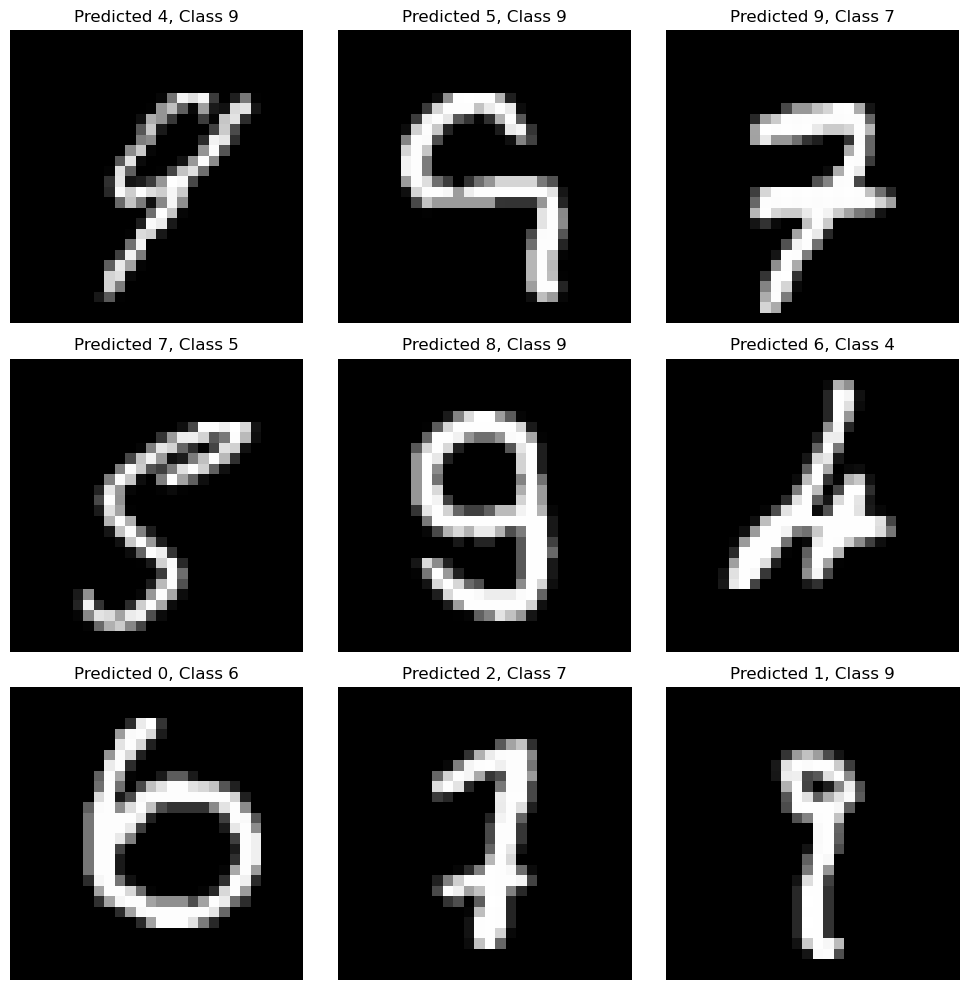

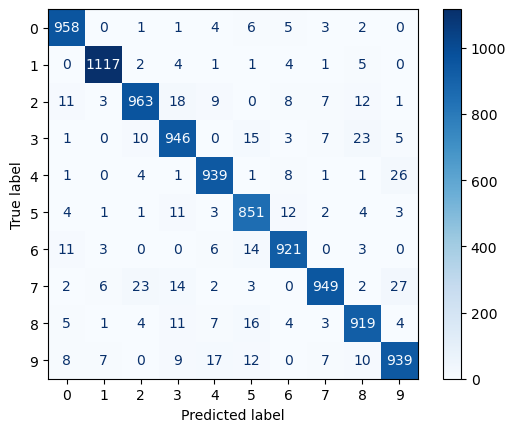

# **第二种方法：用CNN实现：**

In [65]:
from keras import layers
CNN_model = Sequential() # 初试一个前馈神经网络

# 增加卷积运算层1， 卷积核数量=32个，卷积核大小3*3，激活函数relu
CNN_model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)))

# 增加池化层1，窗口（感受野）2*2
CNN_model.add(layers.MaxPooling2D((2,2)))

# 增加卷积运算层2，卷积核数量=64个，卷积核大小3*3，激活函数relu
CNN_model.add(layers.Conv2D(64, (3,3), activation='relu'))

# 增加池化层2，池化窗口（感受野）2*2
CNN_model.add(layers.MaxPooling2D((2,2)))

# 增加卷积运算层3，卷积核数量=64个，卷积核大小3*3，激活函数relu
CNN_model.add(layers.Conv2D(64, (3,3), activation='relu'))

# 添加全连接层，即MLP
CNN_model.add(layers.Flatten())
CNN_model.add(layers.Dense(64, activation='relu'))
CNN_model.add(layers.Dense(10, activation='softmax'))

In [67]:
# 编译模型
CNN_model.compile(optimizer='rmsprop',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

In [69]:
# 训练模型

CNN_model.fit(x_train, y_train_onehot, epochs=10, batch_size=128)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.8242 - loss: 0.5482
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - accuracy: 0.9814 - loss: 0.0594
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.9884 - loss: 0.0388
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.9911 - loss: 0.0291
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.9932 - loss: 0.0222
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.9952 - loss: 0.0160
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.9962 - loss: 0.0125
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.9966 - loss: 0.0114
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - accuracy: 0.9971 - loss: 0.0086
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - accuracy: 0.9977 - loss: 0.0069


In [70]:
# 评估模型
test_loss, test_acc = CNN_model.evaluate(x_test, y_test_onehot)
print(test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 16ms/step - accuracy: 0.9909 - loss: 0.0344
0.9934999942779541


# **用全连接网络实现波士顿房价预测**

In [41]:
from keras.datasets import boston_housing #导入波士顿房价数据集
from keras.models import Sequential #顺序模型
from keras.layers import Dense
from sklearn.preprocessing import StandardScaler

In [42]:
(train_x, train_y), (test_x, test_y) = boston_housing.load_data()

print(train_x.shape)
print(test_x.shape)
print(train_y.shape)
print(test_y.shape)
print(train_x[0])

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
(404, 13)
(102, 13)
(404,)
(102,)
[  1.23247   0.        8.14      0.        0.538     6.142    91.7
   3.9769    4.      307.       21.      396.9      18.72   ]


In [43]:
sc = StandardScaler()
train_x = sc.fit_transform(train_x)
test_x = sc.fit_transform(test_x)
print(train_x[0])
print(test_x[0])

[-0.27224633 -0.48361547 -0.43576161 -0.25683275 -0.1652266  -0.1764426
  0.81306188  0.1166983  -0.62624905 -0.59517003  1.14850044  0.44807713
  0.8252202 ]
[ 2.8040301  -0.50784934  0.96960877 -0.32969024  1.23174581  0.11934137
  1.14739788 -0.91935276  1.60609286  1.40778227  0.90513041 -4.27829517
  2.51324773]


In [44]:
model = Sequential()#先建立一个顺序模型
#向顺序模型里加入第一个隐藏层，第一层一定要有一个输入数据的大小，需要有input_shape参数
#model.add(Dense(n_hidden_1, activation='relu', input_shape=(13,)))
model.add(Dense(64, activation='relu', input_dim=13)) #这个input_dim和input_shape一样，就是少了括号和逗号
model.add(Dense(64, activation='relu'))
model.add(Dense(1)) #因为我们是预测房价，不是分类，所以最后一层可以不用激活函数

C:\Users\12518\anaconda\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [45]:
model.compile(loss='mse', optimizer=Adam(learning_rate=0.001), metrics=['mae'])
#因为我们这是预测房价，一个线性回归预测，所以loss跟分类是不一样的。
#我们这里要用mean_squared_error 可简写成mse optimizer
#我这里用rmsprop大家可以用adam其它梯度下降优化函数，
#正确率我们这里用mae平均绝对误差

In [46]:
#训练神经网络
history = model.fit(train_x, train_y, batch_size=10, epochs=20)

Epoch 1/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 575.2879 - mae: 21.9681
Epoch 2/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 347.5567 - mae: 16.2657
Epoch 3/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 79.3122 - mae: 6.3142
Epoch 4/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 41.2420 - mae: 4.3581
Epoch 5/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 34.4470 - mae: 3.8257
Epoch 6/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 19.2723 - mae: 3.3573
Epoch 7/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 21.4866 - mae: 3.3996
Epoch 8/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 20.4546 - mae: 3.1238
Epoch 9/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 16.9901 - mae: 2.9711
Epoch 10/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 17.4260 - mae: 2.8442
Epoch 11/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 13.0894 - mae: 2.6620
Epoch 12/20
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 14.6373 - mae: 2.7659
Epoch 13/20
41/41 ━━━━━━━━━━━━━━━

In [47]:
# 预测
pred_test_y = RNN_model.predict(test_x)


NameError: name 'RNN_model' is not defined

In [ ]:
#绘图
import matplotlib.pyplot as plt

# 设置图形大小
plt.figure(figsize=(8, 4), dpi=80)
plt.plot(range(len(test_y)), test_y, ls='-.',lw=2,c='r',label='真实值')
plt.plot(range(len(pred_test_y)), pred_test_y, ls='-',lw=2,c='b',label='预测值')

# 绘制网格
plt.grid(alpha=0.4, linestyle=':')
plt.legend()
plt.xlabel('number') #设置x轴的标签文本
plt.ylabel('房价') #设置y轴的标签文本

# 展示
plt.show()

# **用RNN实现波士顿房价预测**

In [ ]:
from keras.layers import SimpleRNN, Dense

# 构建 RNN 模型
RNN_model = Sequential()
RNN_model.add(SimpleRNN(50, activation='relu', input_shape=(train_x.shape[1], 1)))
RNN_model.add(Dense(1))  # 输出层
RNN_model.compile(optimizer='adam', loss='mean_squared_error')

In [ ]:
# 训练模型
history=RNN_model.fit(train_x, train_y, epochs=100, batch_size=32)

In [ ]:
# 绘制损失曲线
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()